# Phase 1 — Neuro-Symbolic Causal Inference: the ML pipeline

**Goal.** Read a short text that lists statistical facts about some variables, decide which
*causal* claims about them are valid, assemble the valid cause→effect claims into a DAG,
and answer intervention ("what if we force X?") questions with a Bayesian network.

**Dataset.** [Corr2Cause](https://huggingface.co/datasets/causal-nlp/corr2cause) (Jin et al., ICLR 2024).
Each example is a *premise* (all correlations / independences in a closed system) and a
*hypothesis* (one causal claim). Label 1 = the claim must be true; 0 = it is not implied.

```
            (1) rule-based         (2) PC algorithm        (3) features      (4) classifier
  TEXT ───────────────────▶ FACTS ─────────────────▶ PDAG ──────────────▶ X ──────────────▶ valid causal triples
                                                                                                │
                                                                (5) graph stage: DAG ─▶ Bayesian network ─▶ do-queries
```

* **Language layer (1)** — turns sentences into facts. Phase 1: regular expressions.
  *Phase 2 swaps in DistilBERT here.*
* **Reasoning layer (2–4)** — causal-discovery rules + an interpretable classifier.
* **Graph layer (5)** — shared by both phases, so the ML vs DL comparison is fair.

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay

from causal_nlp.data import load_split, load_refactorization_test, load_paraphrase_test
from causal_nlp.parsing import parse_premise, parse_hypothesis, RELATIONS
from causal_nlp.causal_rules import pc_from_premise, equivalent_dags, support
from causal_nlp.features import (build_feature_table, analyse_premise, RELATION_FEATURES,
                                 TEXT_FACT_FEATURES, PC_GRAPH_FEATURES, SUPPORT_FEATURES, ALL_FEATURES)
from causal_nlp import graph_stage as gs

SEED = 42
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data

We use the official train / dev / test split. The test set is small (21 premises, 1,162 hypotheses)
but every premise comes with *all* its hypotheses, which is exactly what the graph stage needs.

Two extra **robustness test sets** from the same authors ask the same questions with
(a) variables renamed (`A,B,C → Z,Y,X`) and (b) hypotheses re-worded (`directly causes → directly affects`).

**Labels.** The original generator had a bug that wrote 6,943 wrong labels (3.3 %).
We use the [corrected labels](https://huggingface.co/datasets/zluke/corr2cause-corrected)
(identical text, labels fixed). Section 4 also reports scores on the original labels.

In [2]:
data = {
    "train": load_split("train"),
    "dev": load_split("dev"),
    "test": load_split("test"),
    "refactorization": load_refactorization_test(),
    "paraphrase": load_paraphrase_test(),
}
pd.DataFrame({name: {"rows": len(df), "premises": df.premise.nunique(),
                     "% valid": round(100 * df.label.mean(), 1)} for name, df in data.items()}).T

,rows,premises,% valid
train,205734.0,2338.0,21.0
dev,1076.0,22.0,14.8
test,1162.0,21.0,16.5
refactorization,2246.0,21.0,16.2
paraphrase,2246.0,21.0,16.2


**Leakage check.** Hypotheses about the same premise are near-duplicates, so splits must be
separated *by premise* ("split documents before extraction"). The official split already does this
for the test set (0 shared premises). Dev shares 2 of its 22 premises with train, so dev is only used as
a secondary check — all headline numbers are on test.

In [3]:
premise_sets = {name: set(data[name].premise) for name in ("train", "dev", "test")}
print("train ∩ test premises:", len(premise_sets["train"] & premise_sets["test"]))
print("train ∩ dev  premises:", len(premise_sets["train"] & premise_sets["dev"]))
print("Variables per premise in train:", data["train"].num_variables.value_counts().sort_index().to_dict())
print("Variables per premise in test: ", data["test"].num_variables.value_counts().sort_index().to_dict())

train ∩ test premises: 0
train ∩ dev  premises: 2
Variables per premise in train: {4: 576, 5: 7524, 6: 197634}
Variables per premise in test:  {2: 6, 3: 48, 4: 72, 5: 514, 6: 522}


In [4]:
example = data["test"][data["test"].num_variables == 3].iloc[[0, 3, 5]]
for _, row in example.iterrows():
    print(f"[label={row.label}] {row.hypothesis}")
print("\nPremise:", example.premise.iloc[0])

[label=0] There exists at least one collider (i.e., common effect) of B and C.
[label=0] B directly causes A.
[label=1] A directly causes C.

Premise: Suppose there is a closed system of 3 variables, A, B and C. All the statistical relations among these 3 variables are as follows: A correlates with C. B correlates with C. However, A is independent of B.


In [5]:
# How many labels the bug-fix changed per split
for split in ("train", "dev", "test"):
    original = load_split(split, corrected=False)
    print(f"{split:5s}: {(original.label != data[split].label).sum():5d} labels changed")

train:  6897 labels changed
dev  :    28 labels changed
test :    18 labels changed


## 2. Stage 1 — Text → facts (rule-based extractor)

Our small **entity schema**: variables are single capital letters; facts are
`correlates(X, Y)` and `independent(X, Y | S)`; hypotheses are one of four relations:

| relation | hypothesis wording | meaning |
|---|---|---|
| `direct` | *X directly causes Y* | X → Y |
| `indirect` | *X causes something else which causes Y* / *X is a cause for Y, but not a direct one* | X → Z → … → Y |
| `collider` | *There exists at least one collider (common effect) of X and Y* | X → … → Z ← … ← Y |
| `confounder` | *There exists at least one confounder (common cause) of X and Y* | X ← … ← Z → … → Y |

The parser keeps every fact tied to its premise id, and rejects self-loops (X causes X).

In [6]:
# Pick a test premise whose graph has both oriented and unoriented edges (a good teaching example)
def mixed(p):
    g = pc_from_premise(parse_premise(p))
    return len(g.nodes) <= 5 and g.directed and g.undirected
text = next(p for p in data["test"].premise.unique() if mixed(p))
facts = parse_premise(text)
print(text, "\n")
print("variables  :", facts.variables)
print("correlated :", sorted("".join(sorted(p)) for p in facts.correlated))
print("independent:", {"".join(sorted(p)): ["{" + ",".join(sorted(s)) + "}" for s in sets]
                       for p, sets in facts.sepsets.items() if sets})
print("\nhypothesis :", parse_hypothesis("There exists at least one collider (i.e., common effect) of A and C."))

Suppose there is a closed system of 5 variables, A, B, C, D and E. All the statistical relations among these 5 variables are as follows: A correlates with C. A correlates with D. A correlates with E. B correlates with E. C correlates with D. C correlates with E. D correlates with E. However, A is independent of B. A and B are independent given C. A and B are independent given C and D. A and B are independent given D. A and D are independent given B and C. A and D are independent given C. B is independent of C. B and C are independent given A. B and C are independent given A and D. B and C are independent given A, D and E. B and C are independent given D. B is independent of D. B and D are independent given A. B and D are independent given A and C. B and D are independent given C. C and E are independent given A, B and D. C and E are independent given A and D. 

variables  : ['A', 'B', 'C', 'D', 'E']
correlated : ['AC', 'AD', 'AE', 'BE', 'CD', 'CE', 'DE']
independent: {'AB': ['{}', '{C}

How much of each test set can the rules read?

In [7]:
coverage = {name: df.hypothesis.map(lambda h: parse_hypothesis(h) is not None).mean()
            for name, df in data.items() if name != "train"}
pd.Series(coverage, name="hypotheses parsed").map("{:.0%}".format).to_frame()

,hypotheses parsed
dev,100%
test,100%
refactorization,100%
paraphrase,0%


The rules read 100 % of the template text — including renamed variables — but **0 %** of the
paraphrased hypotheses. Hand-written patterns do not generalise to new wording.
This is the gap Phase 2 (DistilBERT) is meant to close.

## 3. Stage 2 — Facts → causal graph (PC algorithm)

The PC algorithm (Spirtes & Glymour; builds on Pearl's d-separation) turns a list of
(in)dependences into a graph in three steps:

1. **Skeleton** — join X and Y if *no* set of other variables makes them independent.
2. **V-structures** — for X – Z – Y with X, Y not joined: if Z is in none of X, Y's separating sets,
   then Z is a common effect: X → Z ← Y. (Conditioning on a common effect creates dependence.)
3. **Meek rules** — orient more edges where the other direction would create a cycle or a new v-structure.

The result is a **PDAG**: some edges have a known direction, others (dashed) cannot be oriented from
correlations alone. A PDAG stands for a small set of **equivalent DAGs** that fit the facts equally well.
A hypothesis is valid only if it holds in **all** of them — we call the fraction the *support*.

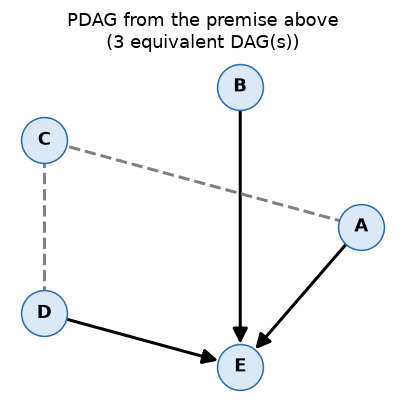

support(direct  , A, E) = 1.00
support(direct  , A, C) = 0.33
support(direct  , C, A) = 0.67
support(indirect, C, E) = 1.00


In [8]:
def draw_pdag(pdag, ax, title):
    g = nx.DiGraph(); g.add_nodes_from(pdag.nodes)
    pos = nx.circular_layout(sorted(pdag.nodes))
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color="#dbe9f6", node_size=900, edgecolors="#2b6cb0")
    nx.draw_networkx_labels(g, pos, ax=ax, font_weight="bold")
    nx.draw_networkx_edges(g, pos, edgelist=list(pdag.directed), ax=ax, arrowsize=20, width=2, node_size=900)
    nx.draw_networkx_edges(g.to_undirected(), pos, edgelist=[tuple(e) for e in pdag.undirected],
                           ax=ax, style="dashed", width=2, edge_color="gray")
    ax.set_title(title); ax.axis("off")

pdag = pc_from_premise(facts)
dags = equivalent_dags(pdag)
fig, ax = plt.subplots(figsize=(4.5, 4))
draw_pdag(pdag, ax, f"PDAG from the premise above\n({len(dags)} equivalent DAG(s))")
plt.show()

(a, b), (c, d) = sorted(pdag.directed)[0], sorted(tuple(sorted(e)) for e in pdag.undirected)[0]
for rel, x, y in [("direct", a, b), ("direct", c, d), ("direct", d, c), ("indirect", d, b)]:
    print(f"support({rel:8s}, {x}, {y}) = {support(dags, rel, x, y):.2f}")

## 4. Stage 3 + 4 — Features and classifiers

Each (premise, hypothesis) becomes one row of numbers. Three feature groups, added one at a time
so we can see how much each reasoning step helps:

| group | features | intuition |
|---|---|---|
| relation | one-hot of the 4 relation types | what is being claimed |
| **text facts** | number of variables, X–Y correlated, X–Y joined in skeleton, #separating sets, smallest separating set, degrees, #common neighbours | read directly off the sentences |
| **PC graph** | X→Y, Y→X, undirected, X ancestor of Y (definite / possible) and reverse, #common children, #common parents | read off the PDAG |
| **support** | fraction of equivalent DAGs where the claim holds, number of equivalent DAGs | "how many possible worlds agree" |

None of the features uses the variable *names*, so renaming variables cannot fool them.

In [9]:
t0 = time.time()
features = {name: build_feature_table(df.input) for name, df in data.items()}
print(f"Built features for {sum(map(len, features.values())):,} rows in {time.time() - t0:.1f}s")
features["test"][["relation", "x", "y"] + TEXT_FACT_FEATURES[:4] + ["edge_x_to_y", "support"]].head(6)

Built features for 212,464 rows in 11.5s


,relation,x,y,n_vars,marginally_correlated,adjacent,n_sepsets,edge_x_to_y,support
0,collider,A,B,2,1,1,0,0,0.0
1,direct,A,B,2,1,1,0,0,0.5
2,indirect,A,B,2,1,1,0,0,0.0
3,direct,B,A,2,1,1,0,0,0.5
4,indirect,B,A,2,1,1,0,0,0.0
5,confounder,A,B,2,1,1,0,0,0.0


### 4.1 Pure-text baseline: TF-IDF + logistic regression
No parsing, no reasoning — just word / n-gram counts of premise and hypothesis.
(This is the fair ML counterpart of an end-to-end transformer in Phase 2.)

In [10]:
def scores(y_true, y_pred):
    return {"precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred)}

EVAL_SETS = ["dev", "test", "refactorization", "paraphrase"]
token = r"(?u)\b\w+\b"  # keep one-letter tokens: the variable names
tfidf_lr = make_pipeline(
    ColumnTransformer([
        ("premise", TfidfVectorizer(token_pattern=token, ngram_range=(1, 3), min_df=5, max_features=50_000, sublinear_tf=True), "premise"),
        ("hypothesis", TfidfVectorizer(token_pattern=token, ngram_range=(1, 3), min_df=2, sublinear_tf=True), "hypothesis"),
    ]),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)
t0 = time.time()
tfidf_lr.fit(data["train"], data["train"].label)
tfidf_results = {s: scores(data[s].label, tfidf_lr.predict(data[s])) for s in EVAL_SETS}
print(f"trained in {time.time() - t0:.0f}s")
pd.DataFrame(tfidf_results).T.round(3)

trained in 37s


,precision,recall,f1,accuracy
dev,0.463,0.874,0.606,0.832
test,0.501,0.943,0.655,0.836
refactorization,0.489,0.240,0.322,0.837
paraphrase,0.267,0.234,0.250,0.772


TF-IDF gets some signal in-distribution but collapses when variables are renamed: it learned a
**shortcut** — in Corr2Cause the variables are named in causal order, so "a later letter causes an
earlier letter" is almost always false. Words are not reasoning.

### 4.2 Feature-based models (ablation)

In [11]:
def predict(model, feats, cols):
    # Rows whose hypothesis could not be parsed get "not valid" (the extractor found no triple).
    pred = np.zeros(len(feats), dtype=int)
    ok = (feats.parsed == 1).values
    if ok.any():
        pred[ok] = model.predict(feats.loc[ok, cols])
    return pred

feature_groups = {
    "relation + text facts": RELATION_FEATURES + TEXT_FACT_FEATURES,
    "+ PC graph": RELATION_FEATURES + TEXT_FACT_FEATURES + PC_GRAPH_FEATURES,
    "+ support (all)": ALL_FEATURES,
}
model_makers = {
    "Logistic Regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Decision Tree (depth 4)": lambda: DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
}
rows, trained = [], {}
y_train = data["train"].label
for group, cols in feature_groups.items():
    for name, make in model_makers.items():
        model = make().fit(features["train"][cols], y_train)
        trained[(group, name)] = model
        row = {"features": group, "model": name}
        row.update({s: f1_score(data[s].label, predict(model, features[s], cols)) for s in ["dev", "test", "refactorization"]})
        rows.append(row)
ablation = pd.DataFrame(rows)
print("F1 of the valid class")
ablation.round(3)

F1 of the valid class


,features,model,dev,test,refactorization
0,relation + text facts,Logistic Regression,0.113,0.146,0.126
1,relation + text facts,Decision Tree (depth 4),0.223,0.239,0.242
2,relation + text facts,Random Forest,0.498,0.503,0.488
3,+ PC graph,Logistic Regression,0.325,0.394,0.347
4,+ PC graph,Decision Tree (depth 4),0.892,0.831,0.860
5,+ PC graph,Random Forest,0.930,0.927,0.895
6,+ support (all),Logistic Regression,0.997,1.000,0.972
7,+ support (all),Decision Tree (depth 4),1.000,0.997,0.997
8,+ support (all),Random Forest,1.000,1.000,0.999


**Reading the table**
* Text facts alone are not enough — the answer depends on *combinations* of facts.
* Adding the PC graph features gives a large jump: the causal-discovery rules do the hard reasoning.
* Adding *support* makes the task almost solved, and a **depth-4 decision tree** is enough.
  Because all three models agree, we pick the simplest one to explain.

### 4.3 Final model: decision tree on all features

In [12]:
final_cols = ALL_FEATURES
final_model = trained[("+ support (all)", "Decision Tree (depth 4)")]
print(export_text(final_model, feature_names=final_cols, decimals=2))

|--- support <= 0.97
|   |--- support <= 0.49
|   |   |--- class: 0
|   |--- support >  0.49
|   |   |--- n_equivalent_dags <= 2.50
|   |   |   |--- n_common_parents <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- n_common_parents >  1.50
|   |   |   |   |--- class: 0
|   |   |--- n_equivalent_dags >  2.50
|   |   |   |--- class: 0
|--- support >  0.97
|   |--- rel_confounder <= 0.50
|   |   |--- class: 1
|   |--- rel_confounder >  0.50
|   |   |--- n_common_parents <= 0.50
|   |   |   |--- degree_x <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- degree_x >  2.50
|   |   |   |   |--- class: 0
|   |   |--- n_common_parents >  0.50
|   |   |   |--- class: 1



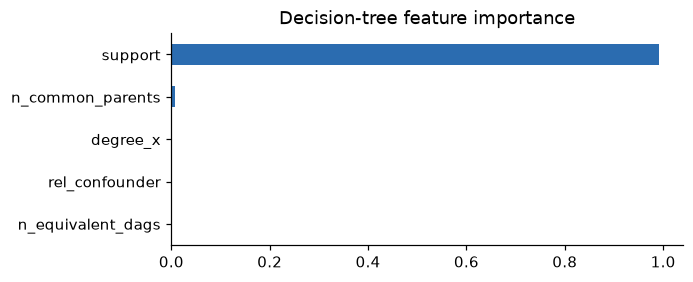

In [13]:
importance = pd.Series(final_model.feature_importances_, index=final_cols).sort_values()
importance[importance > 0].plot.barh(figsize=(6, 2.5), color="#2b6cb0", title="Decision-tree feature importance")
plt.show()

The tree's main rule is simply **"valid if support ≈ 1"** — i.e. *a causal claim is entailed only if
it holds in every DAG consistent with the data*. The small extra branch for `confounder`
absorbs a quirk in how the dataset generator defined "common cause".

,precision,recall,f1,accuracy,n valid
direct,1.0,1.000,1.000,1.000,73
indirect,1.0,1.000,1.000,1.000,36
collider,1.0,1.000,1.000,1.000,68
confounder,1.0,0.933,0.966,0.995,15


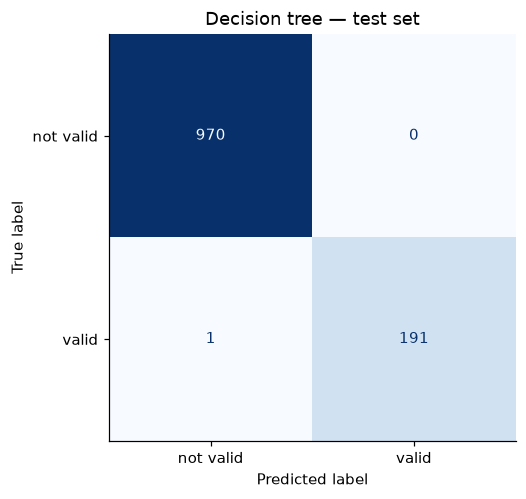

In [14]:
test_feats = features["test"]
test_pred = predict(final_model, test_feats, final_cols)
per_relation = pd.DataFrame({rel: scores(data["test"].label[test_feats.relation == rel], test_pred[(test_feats.relation == rel).values])
                             for rel in RELATIONS}).T
per_relation["n valid"] = [int(data["test"].label[test_feats.relation == r].sum()) for r in RELATIONS]
display(per_relation.round(3))
ConfusionMatrixDisplay.from_predictions(data["test"].label, test_pred, display_labels=["not valid", "valid"],
                                        cmap="Blues", colorbar=False)
plt.title("Decision tree — test set"); plt.show()

### 4.4 Robustness and comparison summary

In [15]:
final_results = {s: scores(data[s].label, predict(final_model, features[s], final_cols)) for s in EVAL_SETS}
original_test = load_split("test", corrected=False)
summary = pd.DataFrame({
    "TF-IDF + LR (text only)": {s: tfidf_results[s]["f1"] for s in EVAL_SETS},
    "Rules + PC + Decision Tree": {s: final_results[s]["f1"] for s in EVAL_SETS},
}).T
summary["test (original labels)"] = [
    f1_score(original_test.label, tfidf_lr.predict(original_test)),
    f1_score(original_test.label, predict(final_model, features["test"], final_cols)),
]
print("F1 of the valid class")
summary.round(3)

F1 of the valid class


,dev,test,refactorization,paraphrase,test (original labels)
TF-IDF + LR (text only),0.606,0.655,0.322,0.25,0.625
Rules + PC + Decision Tree,1.000,0.997,0.997,0.00,0.949


* The neuro-symbolic ML pipeline is near-perfect on template text and **unaffected by renaming**
  (its features never look at names).
* Both models fail on **paraphrased** hypotheses; the rule pipeline scores 0 because its parser
  returns nothing. Fixing the *language* side without losing the *reasoning* side is Phase 2's job.

## 5. Stage 5 — Graph stage: triples → DAG → Bayesian network → do-queries

Only triples the classifier marks **valid** ("reviewed predictions") enter the graph stage.
For each test premise we take the predicted `X directly causes Y` triples, add them from most to
least confident, and **skip any edge that would close a cycle** (a DAG cannot contain one).

In [16]:
test = data["test"]
triples = pd.DataFrame({
    "premise_id": test.premise_id, "relation": test_feats.relation, "x": test_feats.x, "y": test_feats.y,
    "label": test.label, "prob": final_model.predict_proba(test_feats[final_cols])[:, 1],
})
premise_info = {pid: analyse_premise(p)[0] for pid, p in test.groupby("premise_id").premise.first().items()}
nodes = {pid: f.variables for pid, f in premise_info.items()}

predicted_dags = gs.dags_from_triples(triples, nodes)
edge_scores = gs.edge_metrics(predicted_dags, triples)
pd.Series(edge_scores).round(3).to_frame("predicted DAGs vs gold edges")

,predicted DAGs vs gold edges
gold_edges,73.0
predicted_edges,73.0
correct,73.0
edge_precision,1.0
edge_recall,1.0
edge_f1,1.0


**Acyclicity check in action** — feeding a deliberately contradictory set of candidate edges:

In [17]:
candidates = [("A", "B", 0.95), ("B", "C", 0.90), ("C", "A", 0.40), ("B", "B", 0.30)]
dag, rejected = gs.build_dag(["A", "B", "C"], candidates)
print("kept    :", list(dag.edges))
print("rejected:", [(c, e) for c, e, _ in rejected], "(cycle C→A→B→C, self-loop B→B)")

kept    : [('A', 'B'), ('B', 'C')]
rejected: [('C', 'A'), ('B', 'B')] (cycle C→A→B→C, self-loop B→B)


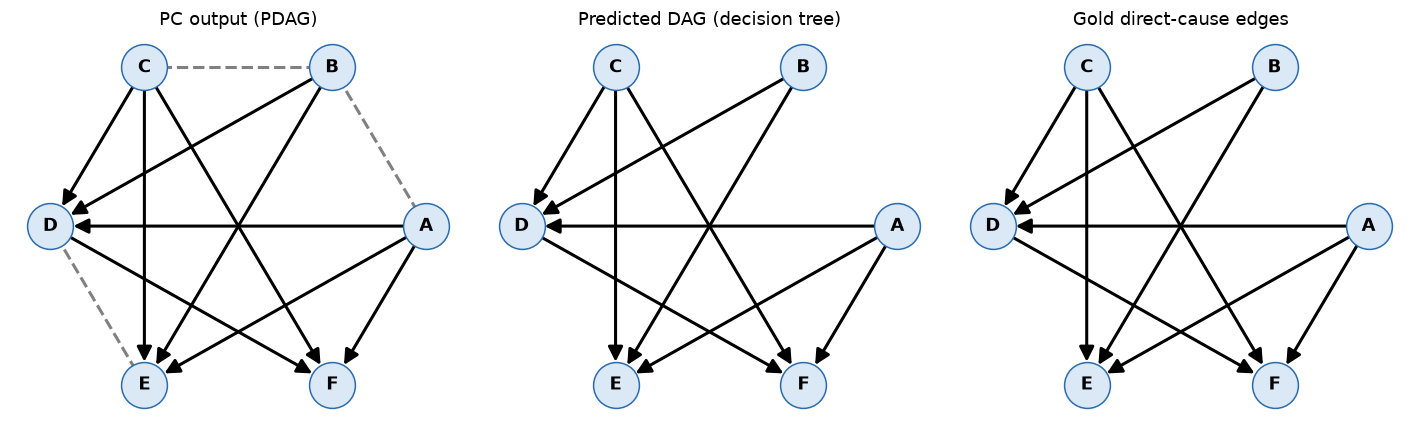

In [18]:
gold_direct = triples[(triples.relation == "direct") & (triples.label == 1)]
pid = max(nodes, key=lambda p: (len(nodes[p]), len(predicted_dags[p].edges)))  # a large example

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
draw_pdag(pc_from_premise(premise_info[pid]), axes[0], "PC output (PDAG)")
for ax, (title, edges) in zip(axes[1:], [
        ("Predicted DAG (decision tree)", list(predicted_dags[pid].edges)),
        ("Gold direct-cause edges", list(zip(gold_direct[gold_direct.premise_id == pid].x,
                                             gold_direct[gold_direct.premise_id == pid].y)))]):
    g = nx.DiGraph(edges); g.add_nodes_from(nodes[pid])
    pos = nx.circular_layout(sorted(g.nodes))
    nx.draw_networkx(g, pos, ax=ax, node_color="#dbe9f6", edgecolors="#2b6cb0", node_size=900,
                     arrowsize=20, width=2, font_weight="bold")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

### 5.1 Bayesian network and intervention queries

Corr2Cause gives the *structure* but no measurements, so each DAG gets simple, clearly illustrative
**noisy-OR** probabilities: every variable is on with 10 % probability by itself, and each active
cause switches it on with 70 % probability. pgmpy then answers **do-queries** —
*"if we force X on vs off, how much does P(Y = 1) change?"* (average causal effect, ACE).

**Known queries** are the ones whose answer is fixed by the gold labels and the text:
* **yes** — X directly or indirectly causes Y (gold label 1);
* **no** — Y causes X (an effect cannot cause its own cause), or X and Y are not even correlated.

In [19]:
correlated = {pid: (f.variables, f.correlated) for pid, f in premise_info.items()}
queries = gs.known_intervention_queries(triples, correlated)
answered = gs.answer_queries(queries, predicted_dags)
answered["correct"] = answered.gold_effect == answered.predicted_effect
query_accuracy = answered.correct.mean()
print(f"{len(answered)} known queries over {answered.premise_id.nunique()} premises — accuracy {query_accuracy:.3f}")
answered.groupby("gold_effect").correct.agg(["size", "mean"]).rename(columns={"size": "queries", "mean": "accuracy"})

242 known queries over 14 premises — accuracy 0.975


,queries,accuracy
gold_effect,,
False,153,1.000000
True,89,0.932584


In [20]:
answered[~answered.correct]

,premise_id,x,y,gold_effect,effect,predicted_effect,correct
4,7,C,E,True,0.0,False,False
13,10,A,D,True,0.0,False,False
30,13,B,D,True,0.0,False,False
31,13,B,E,True,0.0,False,False
72,19,B,E,True,0.0,False,False
73,19,B,F,True,0.0,False,False


The few misses are chains X → … → Y that pass through an edge whose direction the correlations
**cannot identify** (a dashed edge in the PDAG). The direct-edge DAG leaves such edges out, so the
Bayesian network cannot see the path. This is a limit of observational data, not of the extractor.

### 5.2 Why the Bayesian network matters: correlation ≠ causation
When X and Y share a common cause, observing X = 1 tells us more about Y than *setting* X = 1 does.

In [21]:
best = None
for pid, dag in predicted_dags.items():
    bn = gs.noisy_or_network(dag)
    for x, y in dag.edges:
        if set(dag.predecessors(x)) & set(dag.predecessors(y)):  # X and Y share a parent
            gap = gs.observational_effect(bn, x, y) - gs.interventional_effect(bn, x, y)
            if best is None or gap > best[0]:
                best = (gap, pid, x, y, bn)
gap, pid, x, y, bn = best
z = sorted(set(predicted_dags[pid].predecessors(x)) & set(predicted_dags[pid].predecessors(y)))
print(f"Premise {pid}: {x} → {y}, common cause(s) {z}")
print(f"  observational  P({y}=1|{x}=1) - P({y}=1|{x}=0)         = {gs.observational_effect(bn, x, y):.3f}")
print(f"  interventional P({y}=1|do({x}=1)) - P({y}=1|do({x}=0)) = {gs.interventional_effect(bn, x, y):.3f}")

Premise 20: E → F, common cause(s) ['A', 'D']
  observational  P(F=1|E=1) - P(F=1|E=0)         = 0.732
  interventional P(F=1|do(E=1)) - P(F=1|do(E=0)) = 0.488


### 5.3 Fitting the network from data with pgmpy
With real measurements (e.g. a clinical table) the probabilities would be **learned**, not assumed.
To show that step we draw 5,000 samples from the reference network above, fit a fresh network with
the *predicted* structure by maximum likelihood, and check that the fitted model gives the same causal effect.

In [22]:
from pgmpy.models import DiscreteBayesianNetwork
samples = bn.simulate(5000, seed=SEED, show_progress=False)
fitted = DiscreteBayesianNetwork(list(predicted_dags[pid].edges))
fitted.add_nodes_from(predicted_dags[pid].nodes)
fitted.fit(samples)
print(f"ACE of {x} on {y}: reference {gs.interventional_effect(bn, x, y):.3f} | fitted from samples {gs.interventional_effect(fitted, x, y):.3f}")

ACE of E on F: reference 0.488 | fitted from samples 0.508


## 6. Results summary (saved for the Phase 2 comparison)

In [23]:
phase1 = pd.DataFrame([
    {"model": "TF-IDF + LR (text only)", "stage": "relation extraction",
     **{f"{s}_f1": tfidf_results[s]["f1"] for s in EVAL_SETS}},
    {"model": "Rules + PC + Decision Tree", "stage": "relation extraction",
     **{f"{s}_f1": final_results[s]["f1"] for s in EVAL_SETS},
     "edge_precision": edge_scores["edge_precision"], "edge_recall": edge_scores["edge_recall"],
     "intervention_query_accuracy": query_accuracy},
])
phase1.to_csv(RESULTS / "phase1_metrics.csv", index=False)
triples.to_csv(RESULTS / "phase1_test_triples.csv", index=False)
phase1.round(3).T

,0,1
model,TF-IDF + LR (text only),Rules + PC + Decision Tree
stage,relation extraction,relation extraction
dev_f1,0.606,1.0
test_f1,0.655,0.997
refactorization_f1,0.322,0.997
paraphrase_f1,0.25,0.0
edge_precision,NaN,1.0
edge_recall,NaN,1.0
intervention_query_accuracy,NaN,0.975


### Take-aways for the viva
1. **Separate language from reasoning.** Rules extract facts; causal-discovery logic (PC) does the
   reasoning; a depth-4 decision tree learns the final decision. Each step is inspectable.
2. **Reasoning features matter most:** F1 goes from about 0.5 (text facts) → about 0.93 (PC graph) → about 1.0 (support).
3. **Text-only ML learns shortcuts** (variable order) and breaks when names change; our features cannot.
4. **The graph stage adds what extraction cannot:** guaranteed acyclicity, probabilities, and
   intervention answers that differ from correlations.
5. **Open gap → Phase 2:** the hand-written parser reads 0 % of paraphrased text. DistilBERT will
   replace the language layer while the reasoning and graph layers stay the same.